# Model basics: where do "model parameters" come from?

In the previous regression lecture we fit `realinc ~ educ` and calculated two numbers: an intercept of about −$14,000 and a slope of about $3,600. Today we will discover where those numbers came from.

This lesson is adapted from Chapter 23, "Model basics", of:

> Wickham, H. & Grolemund, G. *R for Data Science.* <https://r4ds.had.co.nz/model-basics.html>

Licensed CC BY-NC-ND 3.0 US. The original uses simulated data (`sim1`). We use our GSS data instead.

## Setup

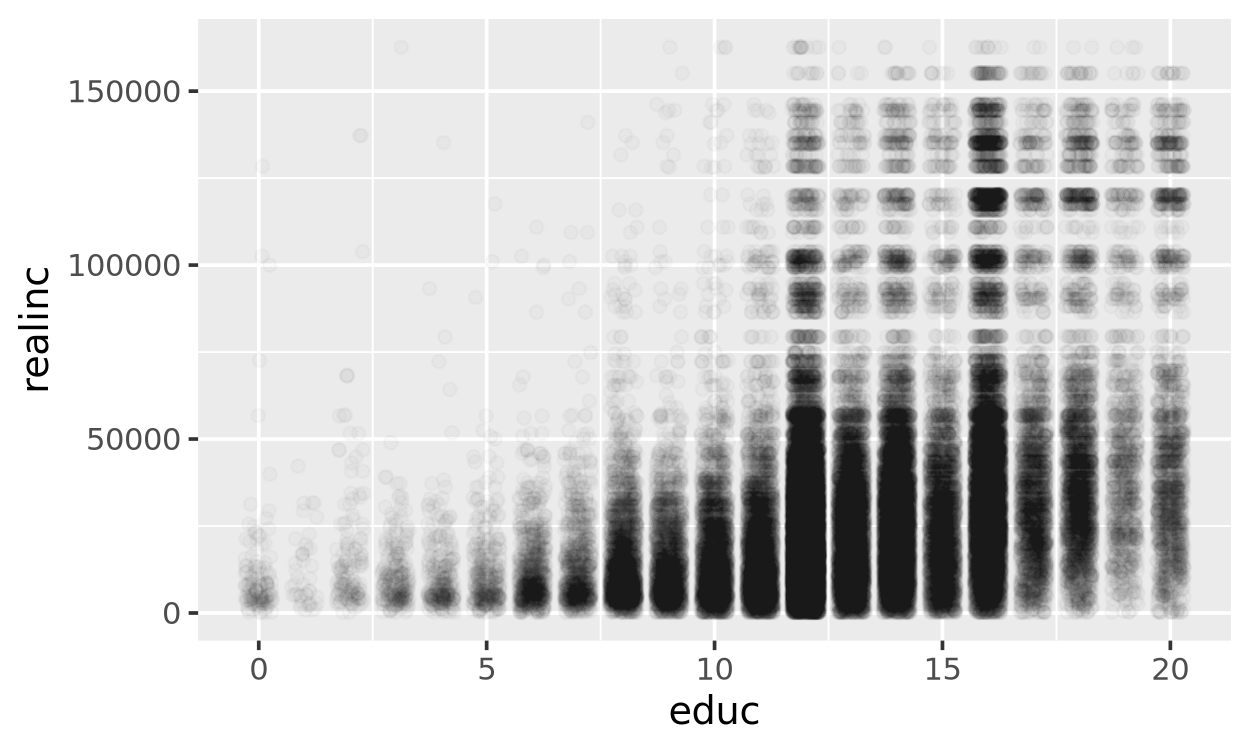

In [15]:
library('tidymodels')

options(repr.plot.res = 250, repr.plot.height = 3, repr.plot.width = 5)

## The data

Load the GSS data set from the regression lecture and drop the rows with missing values.

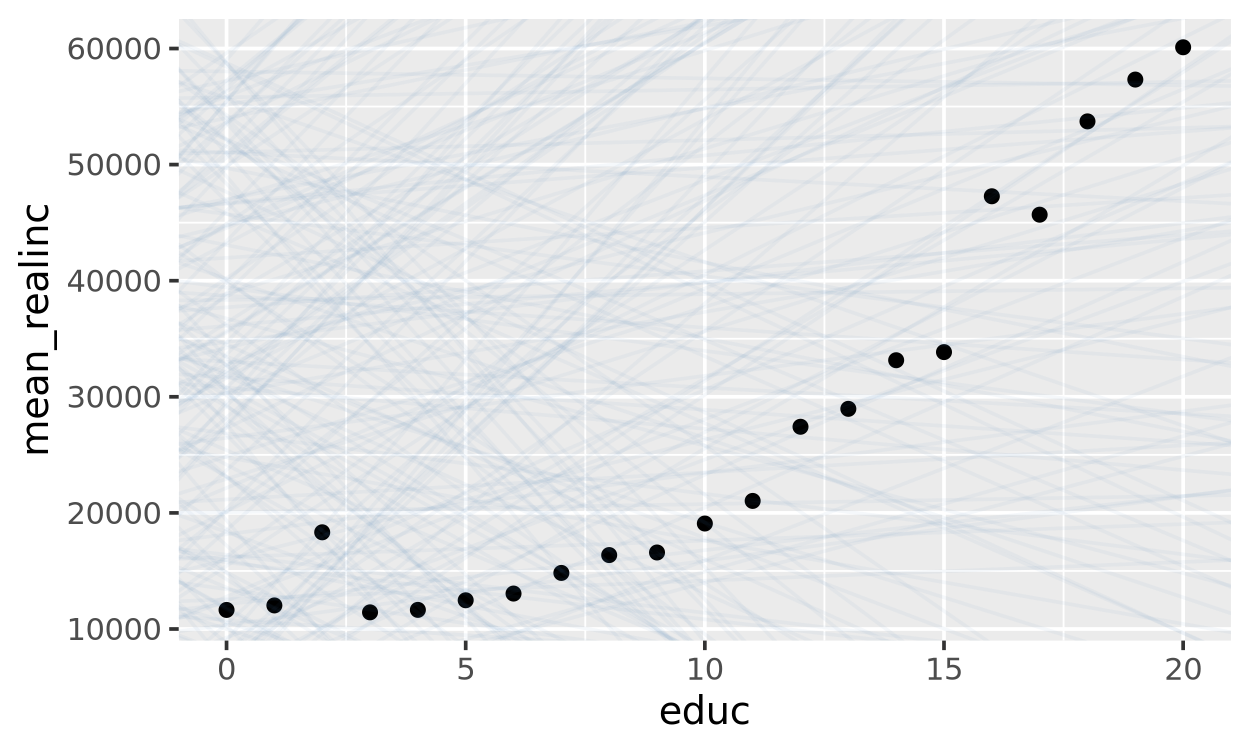

In [17]:
gss = read.csv('https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/gss_subset.csv')

gss <- gss |> drop_na(realinc, educ)

gss |> glimpse()

If we plot every person, the points pile up on top of each other (i.e. there is lots of overplotting). `geom_jitter()` moves the points around a bit and `alpha` makes them transparent. Together, they show the trend in the data.

In [21]:
calc_rmse <- function(intercept, slope, data) {
    predicted <- intercept + slope * data$educ
    sqrt(mean((data$mean_realinc - predicted)^2))
}

In [22]:
param_grid <- param_grid |>
    mutate(rmse = map2_dbl(intercept, slope, calc_rmse, data = educ_means))

param_grid

    intercept slope       rmse     
1   23119.963 -2311.7054  39969.559
2    8031.999  2765.9537  10977.551
3   27405.555  4487.7712  47410.398
4   55946.047 -4338.6715  44006.901
5   38624.935  2401.4695  36249.446
6   11841.809 -2245.4209  47533.732
7   58425.403 -1938.8321  29869.225
8   49746.822  4423.2121  68380.237
9    7106.351 -1673.0242  44734.292
10  30331.805   698.5900  16128.156
11  31978.904  2860.1801  34314.043
12  43405.851  4299.9045  60832.697
13  18161.742   529.0409  13703.069
14  50607.563  3373.4075  58010.477
15  19360.203 -4869.4467  71918.320
16  18348.435 -1457.5705  33722.104
17   7837.791 -1625.0955  43584.982
18  23680.733  3827.6733  36544.345
19  53584.492 -4593.2852  47234.302
20  46802.075 -4095.9696  45348.236
21  44549.530  1681.2774  35298.411
22   9266.077  1533.3745   8757.102
23   7799.010 -1479.9404  41941.972
24  50971.696 -4512.2157  47563.366
25  53434.837  4217.5914  69778.467
26  27629.659  4333.1313  45906.038
27  29232.330  3844.6894  42

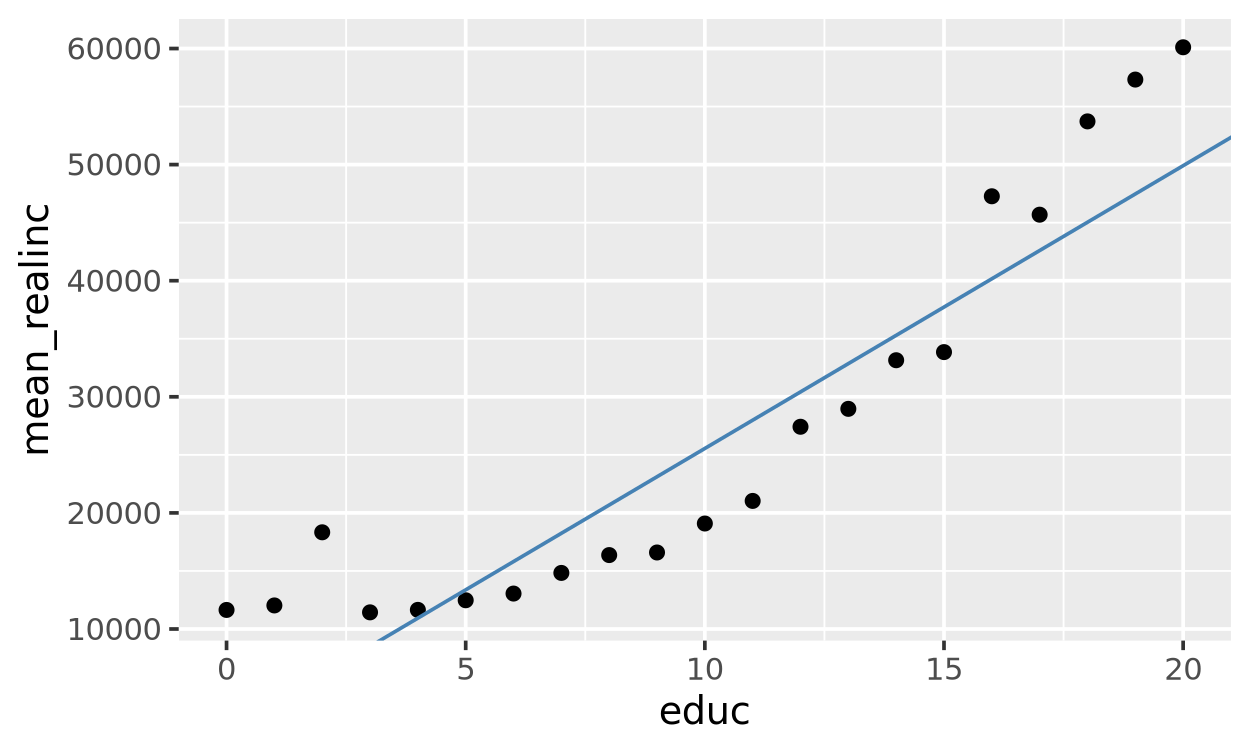

In [23]:
best_model <- param_grid |>
    slice_min(rmse, n = 1)

educ_means |>
    ggplot(aes(x = educ, y = mean_realinc)) +
    geom_point() +
    geom_abline(
        data = best_model,
        aes(intercept = intercept, slope = slope),
        color = "steelblue"
    )

Steps for creating a model:
1. Pick the model form: a linear model

$$ \text{realinc}_i = \beta_0 + \beta_1 \cdot \text{educ}_i + \varepsilon_i $$

2. Design a way to evaluate different model parameters.
3. Optimize our parameter values.

In [28]:
intercept = 2000
slope = 3000

pred = intercept + slope * gss$educ
resid  = gss$realinc - pred
mean(resid^2)
sqrt(mean(resid^2, na.rm = TRUE))

[1] 29721.24

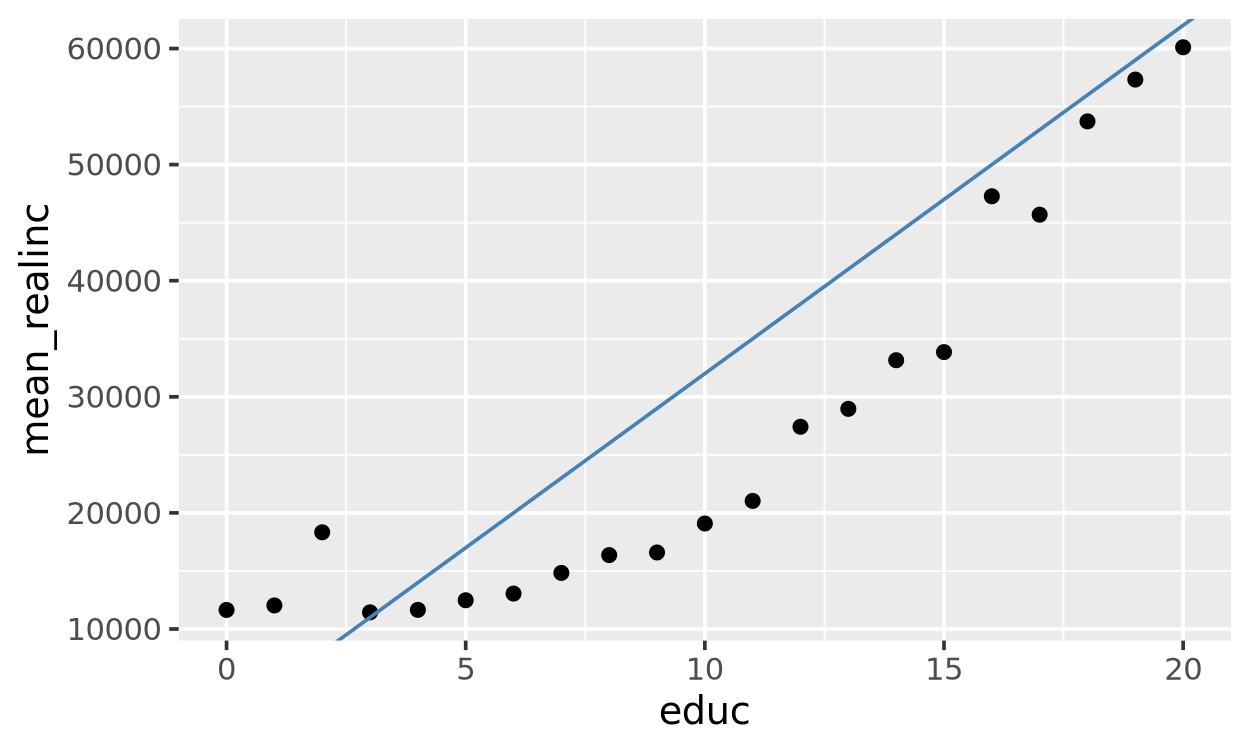

In [29]:
educ_means |>
    ggplot(aes(x = educ, y = mean_realinc)) +
    geom_point() +
    geom_abline(
        intercept = intercept,
        slope = slope,
        color = "steelblue"
    )

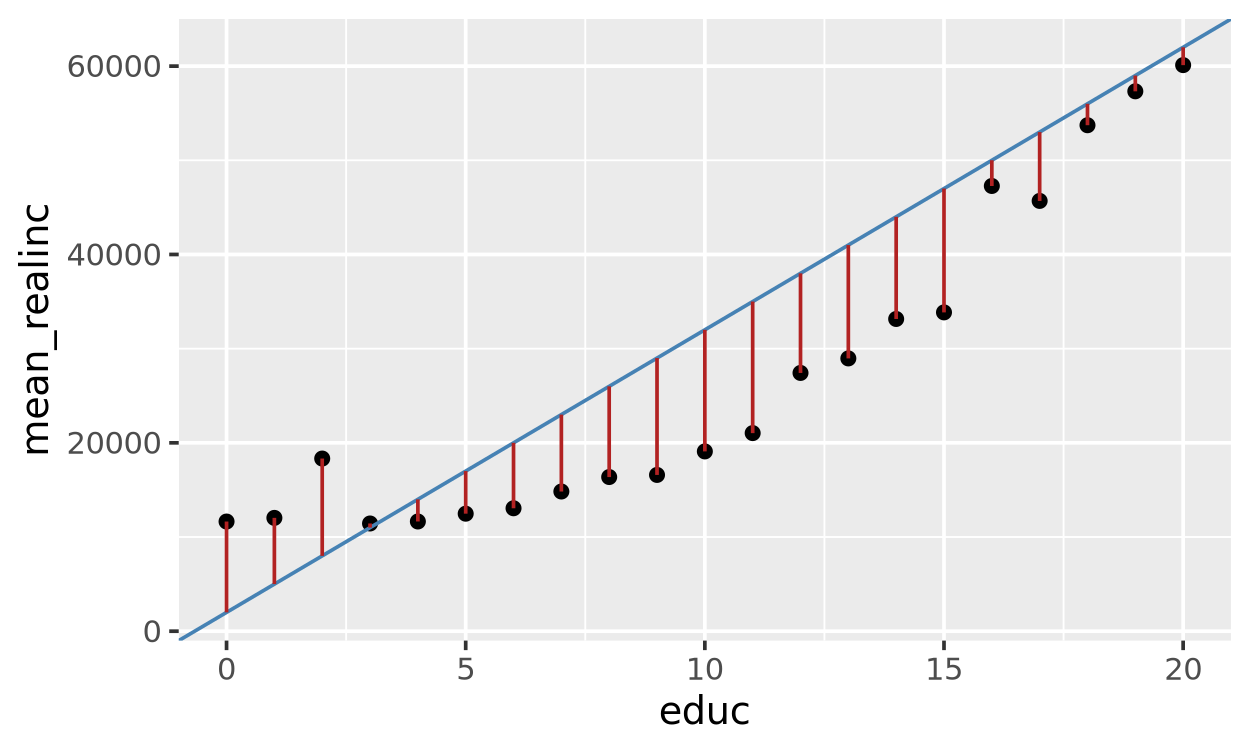

In [30]:
educ_means |>
    mutate(predicted = intercept + slope * educ) |>
    ggplot(aes(x = educ, y = mean_realinc)) +
    geom_point() +
    geom_abline(
        intercept = intercept,
        slope = slope,
        color = "steelblue"
    ) +
    geom_segment(
        aes(xend = educ, yend = predicted),
        color = "firebrick"
    )

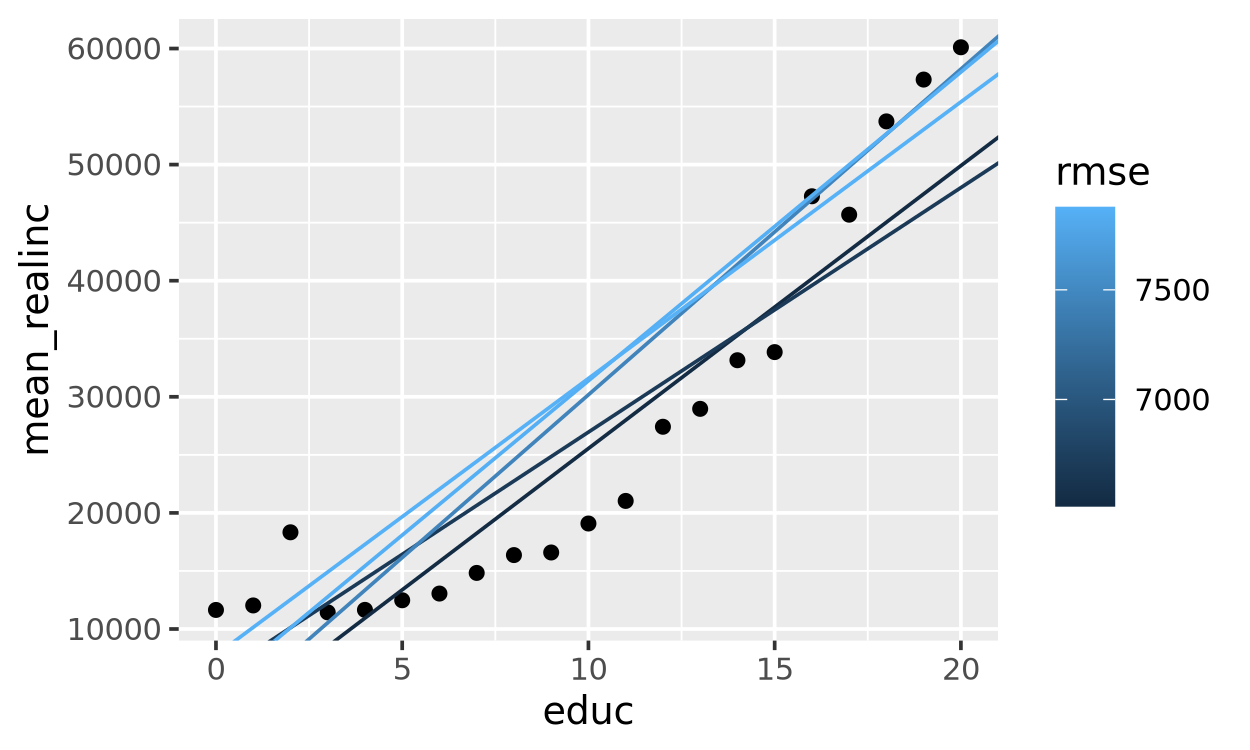

In [31]:
top_models <- param_grid |>
    slice_min(rmse, n = 5)

educ_means |>
    ggplot(aes(x = educ, y = mean_realinc)) +
    geom_point() +
    geom_abline(
        data = top_models,
        aes(intercept = intercept, slope = slope, color = rmse)
    )